## Workshop 3: Segmentación de clientes con Clustering (K-Means vs. Agglomerative vs. DBSCAN)

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("./data/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [24]:
df.shape

(200, 5)

In [25]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [26]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [28]:
df.drop(columns=["CustomerID"], inplace=True)
#2.2

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Gender                  200 non-null    str  
 1   Age                     200 non-null    int64
 2   Annual Income (k$)      200 non-null    int64
 3   Spending Score (1-100)  200 non-null    int64
dtypes: int64(3), str(1)
memory usage: 6.4 KB


### Preguntas Fase 0

**¿Hay valores nulos?**
No. `isnull().sum()` da 0 en todas las columnas y `info()` muestra 200 registros no nulos en cada una, así que no hay que imputar nada.

**¿Qué tipo de dato tiene cada columna?**
`CustomerID`, `Age`, `Annual Income (k$)` y `Spending Score (1-100)` son `int64`, o sea numéricas. `Gender` es `object` y es la única categórica (Male/Female). Ojo que en nuestro csv la columna se llama `Gender` y no `Genre` como dice el enunciado.

Con el `describe()` también se ve que las escalas son muy distintas: la edad va de 18 a 70, el ingreso de 15 a 137 y el score de 1 a 99. Eso lo tenemos en cuenta más abajo para la estandarización.

**Codificación de Gender:** como solo tiene dos categorías y no hay un orden entre ellas, usamos One-Hot con `drop='first'`, que deja una sola columna `Gender_Male` (1 = hombre, 0 = mujer). Al final es lo mismo que hacer un `.map({"Male": 1, "Female": 0})`.

In [30]:
#2.3
# Codificación One-Hot de Gender (drop='first' deja solo Gender_Male)
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded_array = encoder.fit_transform(df[['Gender']])

df_encoded = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(['Gender']),
    dtype=int,
    index=df.index,
)

# Reemplazamos la columna original por la codificada
df = pd.concat([df.drop(columns=['Gender']), df_encoded], axis=1)

In [31]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


In [32]:
features = ["Gender_Male", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

**¿Por qué estandarizar antes de K-Means, Agglomerative o DBSCAN?**
Los tres métodos trabajan con distancias euclidianas, entonces si no escalamos, la variable con el rango más grande es la que manda. El ingreso va de 15 a 137 (desviación de 26.3) y la edad de 18 a 70 (desviación de 14), así que una diferencia de 30 k$ en ingreso pesaría mucho más que una diferencia de 30 años en edad, y `Gender_Male`, que solo vale 0 o 1, prácticamente no contaría. Con `StandardScaler` todas quedan con media 0 y desviación 1 y aportan parecido a la distancia. En DBSCAN es todavía más importante porque `eps` es un radio fijo y solo tiene sentido si todas las variables están en la misma escala.

Fase 3

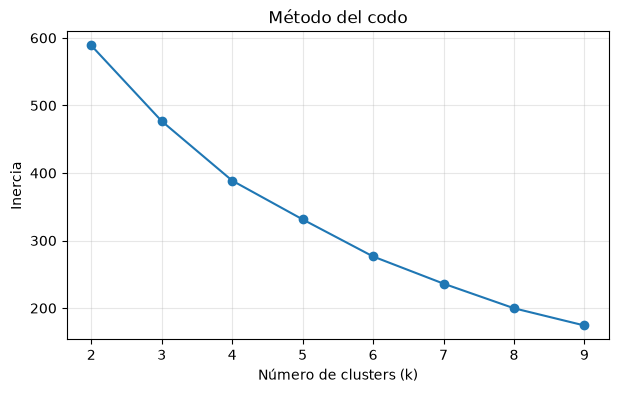

In [33]:
import matplotlib.pyplot as plt

inertias = []
ks = range(2, 10)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

In [34]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


results = []

for k, inertia in zip(ks, inertias):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    results.append({
        "k": k,
        "Inercia": inertia,
        "Silhouette Score": silhouette_score(X_scaled, labels_k),
    })

df_kmeans = pd.DataFrame(results).set_index("k")
df_kmeans.round(4)


,Inercia,Silhouette Score
k,,
2,588.8027,0.2518
3,476.7876,0.2595
4,388.7179,0.2984
5,331.3099,0.3041
6,276.4118,0.3311
7,236.2049,0.3574
8,199.7505,0.3880
9,174.2355,0.4031


In [35]:
# K-Means

k=4
model = KMeans(
    n_clusters=k,     
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X_scaled)

### Preguntas K-Means

**¿El codo de la curva de inercia coincide con el k de mayor Silhouette?**
No, ya que la inercia va bajando sin un codo marcado. Ahí vemos que las caídas son grandes hasta k = 4 (baja 112 de k=2 a k=3 y 88 de k=3 a k=4) y luego se va suavizando (57, 55, 40...), así que el codo razonable nos queda en k = 4. El Silhouette, en cambio, sube con cada k y su máximo está en k = 9 (0.4031), que es el último valor probado, por lo que no marca un número natural de grupos. Además todos los valores son bajos, ninguno pasa de 0.41.

**¿Qué k seleccionarían?**
k = 4. Es donde la inercia empieza a dejar de caer fuerte, y el Silhouette da un salto al pasar de k = 3 a k = 4 (0.2595 a 0.2984) y ya casi no mejora en k = 5 (0.3041). Con 200 clientes, además, 4 grupos mantienen tamaños manejables para interpretar. Si subimos a k = 8 o 9 mejora el score, pero nos deja grupos de 20 a 25 clientes que son difíciles de describir.

Fase 4

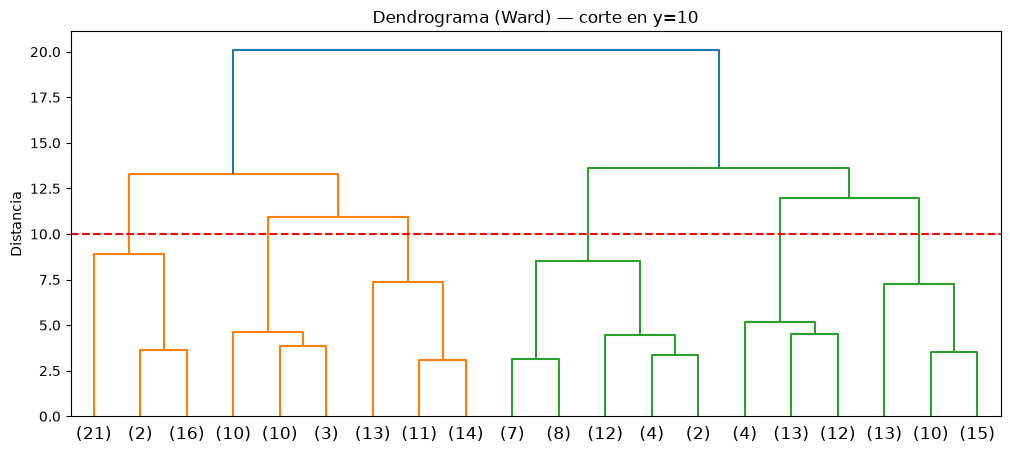

In [36]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)   # solo las 20 ramas de arriba, se lee mejor
plt.axhline(y=10, color="red", linestyle="--")  # el corte
plt.title("Dendrograma (Ward) — corte en y=10")
plt.ylabel("Distancia")
plt.show()

In [37]:
from sklearn.metrics import silhouette_score

# Silhouette para k = 2..8
rows = []
for k in range(2, 9):
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = agg.fit_predict(X_scaled)
    rows.append({"k": k, "Silhouette Score": silhouette_score(X_scaled, labels_k)})

agg_results = pd.DataFrame(rows)
agg_results

,k,Silhouette Score
0,2,0.241780
1,3,0.248345
2,4,0.263226
3,5,0.286994
4,6,0.310245
5,7,0.345558
6,8,0.378880


In [38]:
best_k_agg = 6
agg_model = AgglomerativeClustering(n_clusters=best_k_agg, linkage="ward")
labels_agglomerative = agg_model.fit_predict(X_scaled)

print("Silhouette:", silhouette_score(X_scaled, labels_agglomerative))

Silhouette: 0.3102445968526053


In [39]:
# Etiquetas a partir del corte (por altura o por número de grupos)
labels_dendro = fcluster(Z, t=10, criterion="distance")   # o: fcluster(Z, 6, criterion="maxclust")
pd.Series(labels_dendro).value_counts()

1    39
6    38
3    38
4    33
5    29
2    23
Name: count, dtype: int64

### Preguntas Agglomerative

**¿Cuántos grupos sugiere el dendrograma?**
6. Entre las alturas 8.9 y 10.9 no hay ninguna unión, así que al cortar en 10 se cruzan 6 ramas. Es el mayor espacio vacío después del de k = 2, y 2 grupos es muy poco para segmentar clientes.

**¿Coincide con el mejor k según Silhouette?**
No, ya que el Silhouette sube sin parar (0.24 con k = 2, 0.31 con k = 6 y 0.38 con k = 8), y k = 8 gana solo por ser el último valor probado, igual que pasó con K-Means. Elegimos k = 6 porque el dendrograma lo muestra con claridad y el score ya es razonable, sin partir a los clientes en grupos demasiado pequeños.

Fase 5

In [40]:
from itertools import product
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.3, 0.5, 0.7, 0.9, 1.1]
min_samples_values = [3, 5, 8, 10]

results = []

for eps, min_samples in product(eps_values, min_samples_values):
    labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

    mask = labels_db != -1
    n_clusters = len(set(labels_db[mask]))
    n_noise = (~mask).sum()

    score = silhouette_score(X_scaled[mask], labels_db[mask]) if n_clusters >= 2 else None

    results.append({
        "eps": eps,
        "min_samples": min_samples,
        "N° clusters": n_clusters,
        "N° ruido": n_noise,
        "Silhouette Score": score,
    })

df_dbscan = pd.DataFrame(results)
df_dbscan.round(4)

,eps,min_samples,N° clusters,N° ruido,Silhouette Score
0,0.3,3,14,144,0.6293
1,0.3,5,1,194,NaN
2,0.3,8,0,200,NaN
3,0.3,10,0,200,NaN
4,0.5,3,18,49,0.4746
5,0.5,5,9,105,0.5395
6,0.5,8,2,169,0.7089
7,0.5,10,2,178,0.7694
8,0.7,3,9,14,0.1322
9,0.7,5,7,37,0.2766


In [41]:
# Modelo final de DBSCAN con los parámetros elegidos
eps_final, min_samples_final = 0.9, 8
labels_dbscan = DBSCAN(eps=eps_final, min_samples=min_samples_final).fit_predict(X_scaled)
labels_kmeans = labels  # K-Means con el k de la celda de K-Means

print("DBSCAN -> clusters:", len(set(labels_dbscan) - {-1}), "| ruido:", (labels_dbscan == -1).sum())

DBSCAN -> clusters: 4 | ruido: 25


### Preguntas DBSCAN

**1. ¿Cuántos clusters encontró DBSCAN con los parámetros que eligieron?**
Con `eps = 0.9` y `min_samples = 8` encontró 4 clusters. Escogimos esta combinación porque es un punto medio: con `eps = 0.5` más de la mitad de los clientes quedan como ruido, y con `eps = 1.1` todo se junta en 2 clusters. Los scores altos de la tabla (0.77 con eps = 0.5 y min_samples = 10) no sirven de mucho porque se calculan solo con los 22 puntos que no son ruido.

**2. ¿Cuántos puntos quedaron como ruido?**
25 clientes quedaron como ruido (12.5%). Ese ruido tiene en promedio un ingreso de 67.7 k$ y un spending score de 19.4, o sea que son sobre todo clientes de ingreso alto que gastan poco y no alcanzan a formar una zona densa.

**3. ¿Qué pasa con el número de clusters si aumentan eps? ¿Y si aumentan min_samples?**
Con `min_samples = 8` fijo, un eps pequeño casi no forma grupos (con 0.3 todo es ruido). Si lo subimos da 2 clusters con 0.5, 5 con 0.7 y 4 con 0.9, y luego baja a 2 con 1.1 cuando los grupos se fusionan, mientras el ruido disminuye siempre (169, 76, 25, 10).

Con `eps = 0.9` fijo, subir `min_samples` aumenta el ruido (8, 13, 25, 46), porque se necesita más densidad para formar un grupo. El número de clusters no baja siempre: pasa de 3 a 2, a 4 y a 5. Con una densidad mínima mayor se rompen uniones débiles entre grupos que antes estaban fusionados, y eso puede separarlos en más clusters.

In [42]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por cada componente: [0.33690046 0.26230645 0.23260639]
Varianza explicada acumulada: 0.8318132878845951


**¿Qué porcentaje de la varianza capturan las 3 componentes? ¿Es suficiente?**
El 83.2% (33.7% + 26.2% + 23.3%). Es suficiente para confiar en la visualización como aproximación, pero se pierde cerca del 17%, así que grupos que se vean mezclados podrían estar mejor separados en el espacio original. La varianza se reparte casi por igual porque con 4 variables poco correlacionadas entre sí ningún componente domina.

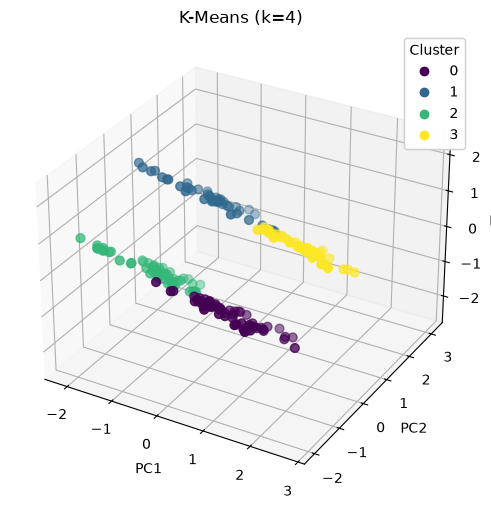

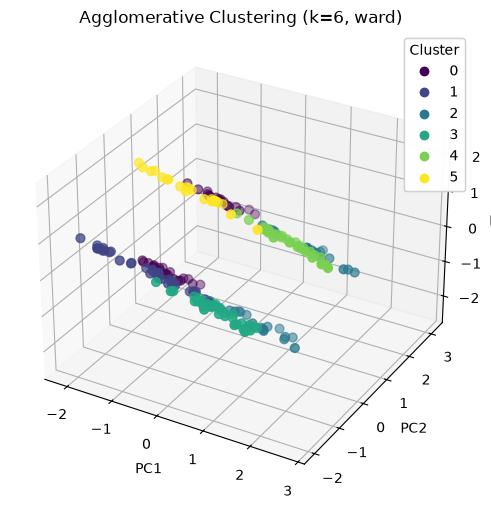

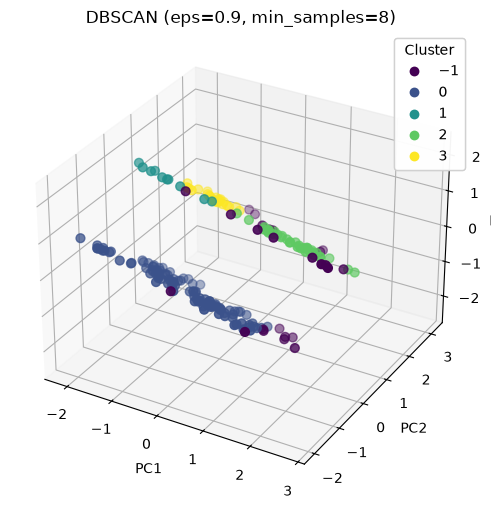

In [43]:
def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title)

    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)

    plt.show()


k_kmeans = len(set(labels_kmeans))
plot_clusters_3d(X_pca, labels_kmeans, f"K-Means (k={k_kmeans})")
plot_clusters_3d(X_pca, labels_agglomerative, f"Agglomerative Clustering (k={best_k_agg}, ward)")
plot_clusters_3d(X_pca, labels_dbscan, f"DBSCAN (eps={eps_final}, min_samples={min_samples_final})")

**Comentario sobre las gráficas:** en K-Means y en Agglomerative se ven grupos que se tocan en los bordes, lo que cuadra con un Silhouette de 0.30. En DBSCAN el ruido (-1) queda pintado con el color más oscuro del `viridis`, muy parecido al del cluster 0, entonces cuesta distinguir qué puntos son ruido y cuáles son del cluster de mujeres. Para leerlo mejor habría que pintar el ruido aparte, por ejemplo en gris.

In [44]:
mask_db = labels_dbscan != -1
k_kmeans = len(set(labels_kmeans))

comparison = pd.DataFrame([
    {
        "Método": "K-Means",
        "Parámetros": f"k = {k_kmeans}",
        "N° de clusters": k_kmeans,
        "N° de puntos de ruido": "N/A",
        "Silhouette Score": silhouette_score(X_scaled, labels_kmeans),
    },
    {
        "Método": "Agglomerative",
        "Parámetros": f'k = {best_k_agg}, linkage="ward"',
        "N° de clusters": len(set(labels_agglomerative)),
        "N° de puntos de ruido": "N/A",
        "Silhouette Score": silhouette_score(X_scaled, labels_agglomerative),
    },
    {
        "Método": "DBSCAN",
        "Parámetros": f"eps = {eps_final}, min_samples = {min_samples_final}",
        "N° de clusters": len(set(labels_dbscan[mask_db])),
        "N° de puntos de ruido": int((~mask_db).sum()),
        # El ruido se excluye del cálculo
        "Silhouette Score": silhouette_score(X_scaled[mask_db], labels_dbscan[mask_db]),
    },
]).set_index("Método")

comparison.round(4)

,Parámetros,N° de clusters,N° de puntos de ruido,Silhouette Score
Método,,,,
K-Means,k = 4,4,N/A,0.2984
Agglomerative,"k = 6, linkage=""ward""",6,N/A,0.3102
DBSCAN,"eps = 0.9, min_samples = 8",4,25,0.2685


**Lectura de la tabla:** los tres métodos quedan cerca, entre 0.27 y 0.31. Agglomerative tiene el score más alto, pero lo hace con 6 clusters, y como vimos el Silhouette sube solo con k, así que no es una comparación justa contra los 4 de K-Means. El de DBSCAN además se calcula dejando por fuera los 25 puntos de ruido. Esto lo discutimos en la Fase 6.

## Fase 6: ¿Cuáles son las clases naturales?

**Conclusión: consideramos que existen 4 grupos y que K-Means es el método más adecuado para definirlos.**

### Por qué K-Means

A igual número de clusters, K-Means obtiene un Silhouette mayor que Agglomerative:

| k | K-Means | Agglomerative (ward) |
|---:|---:|---:|
| 4 | 0.2984 | 0.2632 |
| 6 | 0.3311 | 0.3102 |

También supera a DBSCAN (0.2685 con eps = 0.9 y min_samples = 8), que además deja 25 clientes como ruido. Ese Silhouette de DBSCAN se calcula sin esos puntos, por lo que no es comparable de forma directa.

### Por qué 4 grupos

Con solo 200 clientes, preferimos no sobresegmentar: con más grupos, cada uno queda con pocos clientes y es más difícil de interpretar. Con k = 4, K-Means forma grupos de tamaño equilibrado (entre 42 y 56 clientes).

### Limitaciones

- El Silhouette de 0.30 indica una separación **moderada**: los grupos se distinguen, pero sus fronteras se solapan en parte.
- Las 3 componentes del PCA capturan el 83.2% de la varianza, así que los gráficos 3D conservan la mayor parte de la información, pero no toda.
- Con k = 4, K-Means separa a los clientes sobre todo por género y edad. El ingreso promedio es casi igual en los cuatro grupos (de 58 a 62 k$).

### Alternativa: 6 grupos

Con k = 6 el Silhouette de K-Means sube a 0.3311, y el dendrograma de Agglomerative también sugiere 6 grupos. Con 6 aparecen dos segmentos de ingreso alto (alrededor de 90 k$) que con 4 quedan mezclados: uno con gasto alto y otro con gasto bajo. Si el negocio necesita separar por ingreso y gasto, 6 es una opción válida.

Fase 7

In [45]:
df["Cluster"] = labels  # las labels del método que seleccionaron en la Fase 6
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,Cluster
0,19,15,39,1,1
1,21,15,81,1,1
2,20,16,6,0,0
3,23,16,77,0,2
4,31,17,40,0,0


In [46]:
from IPython.display import display

cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

display(df.groupby("Cluster")[cols].mean().round(1))
display(df.groupby("Cluster")[cols].median())
display(df.groupby("Cluster")["Gender_Male"].value_counts(normalize=True))

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,47.8,58.1,34.9
1,28.0,62.2,64.8
2,28.4,60.4,68.2
3,52.7,62.2,30.6


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,48.0,55.5,39.5
1,28.0,65.5,68.5
2,29.5,62.5,73.0
3,52.5,62.0,35.5


Cluster  Gender_Male
0        0              1.0
1        1              1.0
2        0              1.0
3        1              1.0
Name: proportion, dtype: float64

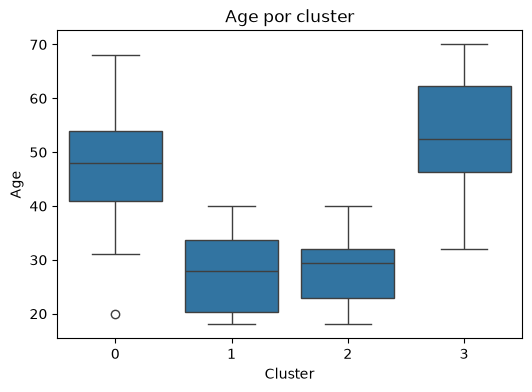

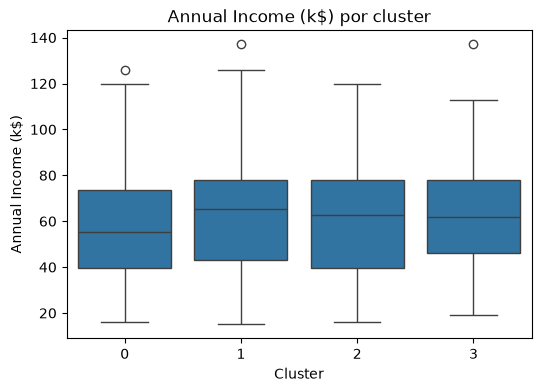

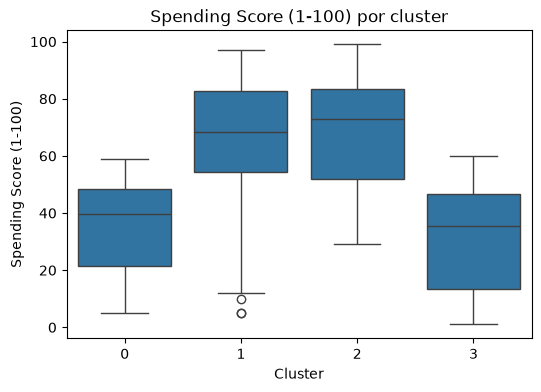

In [47]:
import seaborn as sns

for col in ["Age", "Annual Income (k$)", "Spending Score (1-100)"]:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Cluster", y=col)
    plt.title(f"{col} por cluster")
    plt.show()


| Cluster | Clientes | % Hombres | Edad promedio | Ingreso promedio (k$) | Spending Score promedio | Interpretación / "persona" |
|---:|---:|---:|---:|---:|---:|---|
| 0 | 56 | 0% | 47.8 | 58.1 | 34.9 | Mujeres adultas (la mitad tiene entre 41 y 54 años) que gastan poco. Clientas de ingreso medio que van al centro comercial pero compran con cuidado. |
| 1 | 46 | 100% | 28.0 | 62.2 | 64.8 | Hombres jóvenes (18 a 40) con gasto alto. Buen segmento para promociones de tecnología, ropa o entretenimiento. |
| 2 | 56 | 0% | 28.4 | 60.4 | 68.2 | Mujeres jóvenes (18 a 40) con el gasto más alto de todos. Es el grupo más rentable y también uno de los más grandes. |
| 3 | 42 | 100% | 52.7 | 62.2 | 30.6 | Hombres mayores (32 a 70) con el gasto más bajo. Tienen ingreso parecido al resto, así que no es falta de plata sino que compran poco. |

Lo primero que se ve en las métricas y en los boxplots es que los 4 grupos salen de cruzar dos cosas: el género (cada cluster es 100% hombres o 100% mujeres) y la edad (jóvenes alrededor de 28 años vs. mayores de casi 50). El spending score sigue a la edad: los dos grupos jóvenes gastan entre 65 y 68 y los dos mayores entre 31 y 35. El ingreso, en cambio, casi no cambia entre clusters (58 a 62 k$ de promedio) y en los boxplots cada cluster tiene ingresos desde 15 hasta más de 120 k$, entonces con k = 4 el ingreso no está ayudando a separar.

Creemos que el género pesa tanto porque después de estandarizar `Gender_Male` solo toma dos valores muy alejados entre sí (más o menos -0.89 y 1.13), entonces cambiar de género "cuesta" en distancia lo mismo que un salto grande de edad o de ingreso, y K-Means prefiere cortar por ahí.

### Pregunta

**¿Algún cluster combina valores que no esperaban? ¿Qué estrategia le darían?**
Sí, aunque con k = 4 no aparece como un cluster aparte. Esperábamos que el ingreso fuera de las variables más importantes y resultó que no separa nada. Dentro de cada grupo están mezclados clientes de ingreso alto y gasto bajo con otros de ingreso alto y gasto alto. Cuando probamos k = 6 en la Fase 6 ese grupo sí sale solo: 29 clientes con ingreso mediano de 86 k$ y spending score promedio de 18. Son además los mismos que DBSCAN marcó como ruido. Es el caso raro, porque tienen con qué gastar y no lo hacen.

A ese grupo le daríamos una estrategia de "atraerlos", no de descuentos: experiencias o servicios premium, programas de fidelización con beneficios exclusivos o marcas que hoy de pronto no encuentran en el centro comercial. Primero toca entender por qué gastan poco (puede que compren en otro lado o que solo vayan por algo puntual), porque con ese ingreso tienen el mayor potencial de crecimiento.

## Fase 8: El cluster como variable objetivo

Usamos las etiquetas de K-Means con k = 4 como `y`. Las features son las mismas 4 variables pero sin escalar, porque el escalado lo hace el `Pipeline` del clasificador.

In [48]:
X = df[["Gender_Male", "Age", "Annual Income (k$)", "Spending Score (1-100)"]]
y = df["Cluster"]

y.value_counts().sort_index()

Cluster
0    56
1    46
2    56
3    42
Name: count, dtype: int64

## Fase 9: Clasificador

Escogimos **KNN**. Tiene sentido para este problema porque K-Means asigna cada cliente al centroide más cercano, entonces un modelo que también decide por cercanía debería aprender bien esas fronteras. Al ser de distancias, va con `StandardScaler` dentro del pipeline.

**¿Por qué stratify?** Los clusters no tienen el mismo tamaño (de 42 a 56 clientes) y el test es de solo 40 clientes. Con `stratify=y` cada cluster queda en train y test con la misma proporción que en el dataset completo. Sin eso podría pasar que un cluster quede con muy pocos ejemplos en test y la métrica de ese cluster no diga nada.

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_test.value_counts().sort_index())

Train: (160, 4) | Test: (40, 4)
Cluster
0    11
1     9
2    11
3     9
Name: count, dtype: int64


In [50]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Probamos algunos vecinos con validación cruzada sobre train (sin tocar el test)
for n in [3, 5, 7, 9]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=n))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(f"n_neighbors={n}: accuracy CV = {scores.mean():.4f}")

n_neighbors=3: accuracy CV = 0.9688
n_neighbors=5: accuracy CV = 0.9688
n_neighbors=7: accuracy CV = 0.9750
n_neighbors=9: accuracy CV = 0.9688


In [51]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

Los valores de `n_neighbors` dan casi lo mismo en validación cruzada (alrededor de 0.97), así que nos quedamos con 5, que es un valor intermedio y no depende tanto de un solo vecino.

In [52]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.975
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.89      0.94         9
           2       1.00      1.00      1.00        11
           3       0.90      1.00      0.95         9

    accuracy                           0.97        40
   macro avg       0.97      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40

[[11  0  0  0]
 [ 0  8  0  1]
 [ 0  0 11  0]
 [ 0  0  0  9]]


## Fase 10: Preguntas de cierre

**1. ¿Qué tan bien logró el clasificador predecir el cluster de un cliente nuevo?**
Muy bien. Acertó 39 de los 40 clientes del test (accuracy de 0.975), y en validación cruzada sobre train también dio alrededor de 0.97, así que no fue suerte del split. Los clusters 0 y 2 (las mujeres) salieron perfectos.

**2. Si el accuracy es casi 1.0, ¿qué dice eso de qué tan separables son los clusters?**
Que en el espacio original los clusters son bastante separables, aunque el Silhouette fuera solo de 0.30. Ayuda mucho que el género divide los clusters de forma perfecta, entonces la mitad del problema es trivial y el modelo solo tiene que separar por edad (y gasto) dentro de cada género. Igual hay que tomarlo con calma: las etiquetas las generó K-Means con estas mismas variables, entonces el clasificador está aprendiendo la regla de K-Means, no confirmando que los grupos existan "de verdad" en los clientes. Un accuracy alto aquí dice que la segmentación es fácil de reproducir para clientes nuevos, que es justo lo que se buscaba.

**3. ¿Los clusters que confundió tenían perfiles parecidos en la Fase 7?**
El único error fue un cliente del cluster 1 (hombres jóvenes, gasto alto) que el modelo puso en el cluster 3 (hombres mayores, gasto bajo). Tiene sentido: los dos son de hombres, entonces la variable que más separa no ayuda, y en edad se solapan entre 32 y 40 años según los boxplots. Un cliente en esa franja de edad y con un gasto intermedio queda justo en la frontera entre los dos, y ahí es donde K-Means y KNN pueden no estar de acuerdo.

## Reflexión final

**¿El método con mayor Silhouette fue el que usaron para definir los segmentos? ¿Por qué?**
No. En la tabla final el score más alto fue el de Agglomerative con k = 6 (0.3102), y en la exploración de DBSCAN hubo valores de hasta 0.77, pero con casi todos los clientes como ruido. Usamos K-Means con k = 4 porque, comparando con el mismo número de clusters, K-Means le gana a Agglomerative (0.2984 vs 0.2632), los grupos quedan balanceados (42 a 56 clientes), no deja a nadie sin segmento como DBSCAN, y cada grupo se puede explicar en una frase. Como el Silhouette sube solo con k, tampoco lo podíamos usar como único criterio.

**Recomendación de marketing por segmento:**
- **Cluster 0 (mujeres adultas, gasto bajo):** campañas de fidelización con descuentos en productos para el hogar y bienestar, que les den razones para volver más seguido.
- **Cluster 1 (hombres jóvenes, gasto alto):** lanzamientos y promociones en tecnología, deportes y entretenimiento, comunicadas por redes sociales.
- **Cluster 2 (mujeres jóvenes, gasto alto):** programa de puntos o membresía con beneficios exclusivos en moda y belleza, para cuidar a las clientas que más gastan.
- **Cluster 3 (hombres mayores, gasto bajo):** ofertas puntuales en servicios y productos prácticos, y facilitarles la visita (parqueadero, horarios) para que se queden más tiempo comprando.